# 🚀 Clase Práctica: Proceso ETL con Python y Análisis Exploratorio (EDA)

**Objetivo:** Aprender a Extraer, Transformar (limpiar y explorar) y Cargar datos desde cero, aplicando buenas prácticas de la industria como la trazabilidad (logging) y el uso de formatos modernos.

**Autor:** [Tu Nombre]  
**Fecha:** Octubre 2026

## 🏗️ Paso 0: Extracción de un dataset público (propinas de restaurante)
Cargaremos el dataset `tips` de Seaborn, que contiene importes de cuentas y propinas. Si no se puede descargar desde GitHub, se usará la copia local `tips.csv`.
Después adaptaremos y ensuciaremos algunos datos para practicar el proceso ETL.


In [10]:
import logging
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import requests
import random
from datetime import datetime, timedelta
import urllib.request
import urllib.error

# 1. CARGAR DATASET PÚBLICO REAL (cuentas y propinas de restaurante)
url_csv = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
# Nota: 'tips' es un dataset real de propinas en restaurantes. 
# Lo adaptaremos para que tenga sentido con tu clase de ETL.

try:
    print("📥 Descargando dataset real desde GitHub...")
    urllib.request.urlretrieve(url_csv, "datos_reales_crudos.csv")
    ruta_csv = "datos_reales_crudos.csv"
except (urllib.error.URLError, TimeoutError) as error:
    ruta_csv = "tips.csv"
    print(f"⚠️ No se pudo descargar el CSV ({error}). Se usará el archivo local: {ruta_csv}")

df_real = pd.read_csv(ruta_csv)

# Adaptamos los nombres de las columnas al contexto de cuentas y propinas
# Limitamos el ejemplo antes de añadir errores para mantenerlo corto y conservar los duplicados
df_real = df_real.head(25).copy()
df_real = df_real.rename(columns={
    'total_bill': 'precio',
    'tip': 'propina',
    'sex': 'genero_cliente',
    'smoker': 'es_fumador',
    'day': 'dia_semana',
    'time': 'turno',
    'size': 'cantidad_personas'
})

# ==========================================
# 2. INYECCIÓN DE ERRORES CONTROLADOS
# ==========================================
df_sucio = df_real.copy()

# D) Fechas mixtas (añadimos una columna de fecha simulada antes de duplicar)
fechas_mixtas = ['2023-10-01', '02/10/2023', '2023-10-03', '04-10-2023', '2023/10/05']
df_sucio['fecha_registro'] = (fechas_mixtas * (len(df_sucio) // len(fechas_mixtas) + 1))[:len(df_sucio)]

# A) Duplicados
df_sucio = pd.concat([df_sucio, df_sucio.iloc[0:2]], ignore_index=True)

# B) Nulos
df_sucio.loc[5, 'precio'] = np.nan
df_sucio.loc[10, 'dia_semana'] = np.nan

# C) Texto sucio
df_sucio['turno'] = df_sucio['turno'].apply(lambda x: f"  {str(x).upper()}  " if pd.notnull(x) else x)

df_sucio.to_csv('ventas_restaurante_sucias.csv', index=False)
print("✅ Dataset público descargado y adaptado. Guardado como 'ventas_restaurante_sucias.csv'")
display(df_sucio.head(10))

📥 Descargando dataset real desde GitHub...
⚠️ No se pudo descargar el CSV (<urlopen error [WinError 10060] Se produjo un error durante el intento de conexión ya que la parte conectada no respondió adecuadamente tras un periodo de tiempo, o bien se produjo un error en la conexión establecida ya que el host conectado no ha podido responder>). Se usará el archivo local: tips.csv
✅ Dataset público descargado y adaptado. Guardado como 'ventas_restaurante_sucias.csv'


,precio,propina,genero_cliente,es_fumador,dia_semana,turno,cantidad_personas,fecha_registro
0,16.99,1.01,Female,No,Sun,DINNER,2,2023-10-01
1,10.34,1.66,Male,No,Sun,DINNER,3,02/10/2023
2,21.01,3.50,Male,No,Sun,DINNER,3,2023-10-03
3,23.68,3.31,Male,No,Sun,DINNER,2,04-10-2023
4,24.59,3.61,Female,No,Sun,DINNER,4,2023/10/05
5,NaN,4.71,Male,No,Sun,DINNER,4,2023-10-01
6,8.77,2.00,Male,No,Sun,DINNER,2,02/10/2023
7,26.88,3.12,Male,No,Sun,DINNER,4,2023-10-03
8,15.04,1.96,Male,No,Sun,DINNER,2,04-10-2023
9,14.78,3.23,Male,No,Sun,DINNER,2,2023/10/05


## ⚙️ Configuración de Trazabilidad (Logging)
> 💡 *Nota para el alumno:* En procesos ETL profesionales, no basta con que el código funcione; debemos dejar un rastro (log) de qué pasó, cuándo y si hubo errores. Esto reemplaza a las tablas de control complejas para este ejercicio introductorio.

In [11]:
# Configuramos el sistema de logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filename='proceso_etl.log',
    filemode='w', # 'w' sobreescribe el archivo en cada ejecución
    encoding='utf-8',
    force=True
)

# Para ver los logs también en la salida del Notebook
console = logging.StreamHandler()
console.setLevel(logging.INFO)
logging.getLogger().addHandler(console)

logging.info("=== INICIO DEL PROCESO ETL ===")

=== INICIO DEL PROCESO ETL ===


## 📥 FASE 1: EXTRACCIÓN (Extract)
Leemos los datos desde la fuente. Usamos un bloque `try-except` para manejar errores de forma controlada.

In [12]:
def extraer_datos(ruta_archivo):
    logging.info(f"Iniciando extracción desde: {ruta_archivo}")
    try:
        df = pd.read_csv(ruta_archivo)
        logging.info(f"Extracción exitosa. Registros cargados: {len(df)}")
        return df
    except Exception as e:
        logging.error(f"Error al extraer datos: {e}")
        raise

# Ejecutamos la extracción
df_crudo = extraer_datos('ventas_restaurante_sucias.csv')
df_crudo.head()

Iniciando extracción desde: ventas_restaurante_sucias.csv
Extracción exitosa. Registros cargados: 27


,precio,propina,genero_cliente,es_fumador,dia_semana,turno,cantidad_personas,fecha_registro
0,16.99,1.01,Female,No,Sun,DINNER,2,2023-10-01
1,10.34,1.66,Male,No,Sun,DINNER,3,02/10/2023
2,21.01,3.50,Male,No,Sun,DINNER,3,2023-10-03
3,23.68,3.31,Male,No,Sun,DINNER,2,04-10-2023
4,24.59,3.61,Female,No,Sun,DINNER,4,2023/10/05


## 🔄 FASE 2: TRANSFORMACIÓN Y EDA (Transform) - Parte 1: Auditoría y Duplicados
Antes de limpiar, debemos **diagnosticar**. El Análisis Exploratorio de Datos (EDA) nos dice *qué* está mal antes de decidir *cómo* arreglarlo.

In [13]:
logging.info("Iniciando fase de Transformación y EDA...")

# 1. Auditoría inicial
logging.info(f"Forma original del dataset: {df_crudo.shape}")
logging.info(f"Valores nulos por columna:\n{df_crudo.isnull().sum()}")

# 2. Manejo de Duplicados
duplicados = df_crudo.duplicated().sum()
logging.info(f"Filas duplicadas encontradas: {duplicados}")

if duplicados > 0:
    df_limpio = df_crudo.drop_duplicates().reset_index(drop=True)
    logging.info("Duplicados eliminados.")
else:
    df_limpio = df_crudo.copy()

Iniciando fase de Transformación y EDA...
Forma original del dataset: (27, 8)
Valores nulos por columna:
precio               1
propina              0
genero_cliente       0
es_fumador           0
dia_semana           1
turno                0
cantidad_personas    0
fecha_registro       0
dtype: int64
Filas duplicadas encontradas: 2
Duplicados eliminados.


## 🔄 FASE 2: TRANSFORMACIÓN - Parte 2: Limpieza de Texto y Nulos (con EDA)
- **Texto:** Normalizaremos `genero_cliente`, `es_fumador`, `dia_semana` y `turno` quitando espacios y usando mayúscula inicial.
- **Nulos:** No imputamos a ciegas. Primero graficamos la distribución de `precio` para decidir cómo imputarlo; para `dia_semana` usaremos la moda.

- El método .strip() elimina los espacios en blanco y los caracteres iniciales y finales de una cadena de texto
- El método str.title() convierte el primer carácter de cada palabra en mayúscula y transforma el resto de las letras de cada palabra a minúsculas

Columnas de texto estandarizadas (strip + title).


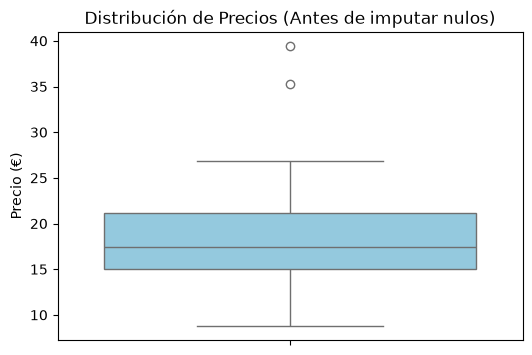

Nulos en 'precio' imputados con la mediana: 17.455€
Nulos en 'dia_semana' imputados con la moda: Sun


In [14]:
# 3. Estandarización de Texto
for columna in ['genero_cliente', 'es_fumador', 'dia_semana', 'turno']:
    df_limpio[columna] = df_limpio[columna].str.strip().str.title()
logging.info("Columnas de texto estandarizadas (strip + title).")

# 4. EDA Visual para decidir imputación de nulos
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_limpio, y='precio', color='skyblue')
plt.title('Distribución de Precios (Antes de imputar nulos)')
plt.ylabel('Precio (€)')
plt.show()

# Imputación: mediana para precio (robusta a outliers) y moda para día de la semana
mediana_precio = df_limpio['precio'].median()
df_limpio['precio'] = df_limpio['precio'].fillna(mediana_precio)
logging.info(f"Nulos en 'precio' imputados con la mediana: {mediana_precio}€")

moda_dia_semana = df_limpio['dia_semana'].mode()[0]
df_limpio['dia_semana'] = df_limpio['dia_semana'].fillna(moda_dia_semana)
logging.info(f"Nulos en 'dia_semana' imputados con la moda: {moda_dia_semana}")

## 🔄 FASE 2: TRANSFORMACIÓN - Parte 3: Tipos de Datos y Nuevas Columnas
Corregimos el formato de `fecha_registro` y creamos una métrica de negocio: el porcentaje de propina sobre el importe de la cuenta.

In [15]:
# 5. Corrección de Tipos de Datos
# errors='coerce' convierte fechas inválidas en NaT en lugar de romper el código
df_limpio['fecha_registro'] = pd.to_datetime(df_limpio['fecha_registro'], format='mixed', dayfirst=True, errors='coerce')
df_limpio['cantidad_personas'] = df_limpio['cantidad_personas'].astype(int)
logging.info("Tipos de datos convertidos correctamente.")

# 6. Ingeniería de características (Feature Engineering)
df_limpio['porcentaje_propina'] = (df_limpio['propina'] / df_limpio['precio'] * 100).round(2)

logging.info(f"Forma final del dataset: {df_limpio.shape}")
print("\n--- VISTA PREVIA DE DATOS LIMPIOS ---")
display(df_limpio.head())

Tipos de datos convertidos correctamente.
Forma final del dataset: (25, 9)



--- VISTA PREVIA DE DATOS LIMPIOS ---


,precio,propina,genero_cliente,es_fumador,dia_semana,turno,cantidad_personas,fecha_registro,porcentaje_propina
0,16.99,1.01,Female,No,Sun,Dinner,2,2023-01-10,5.94
1,10.34,1.66,Male,No,Sun,Dinner,3,2023-10-02,16.05
2,21.01,3.50,Male,No,Sun,Dinner,3,2023-03-10,16.66
3,23.68,3.31,Male,No,Sun,Dinner,2,2023-10-04,13.98
4,24.59,3.61,Female,No,Sun,Dinner,4,2023-05-10,14.68


## 📤 FASE 3: CARGA (Load)
Guardamos los datos limpios. Usaremos dos formatos:
1. **CSV:** Universal y legible por humanos.
2. **Parquet:** Formato columnar moderno, mucho más rápido y ligero, estándar en ingeniería de datos actual.

In [16]:
def cargar_datos(df, ruta_base):
    logging.info(f"Iniciando carga de datos...")
    try:
        ruta_csv = ruta_base.replace('.csv', '_limpio.csv')
        ruta_parquet = ruta_base.replace('.csv', '_limpio.parquet')
        
        df.to_csv(ruta_csv, index=False)
        df.to_parquet(ruta_parquet, index=False)
        
        logging.info(f"✅ Carga completada exitosamente en:\n - {ruta_csv}\n - {ruta_parquet}")
    except Exception as e:
        logging.error(f"Error al cargar datos: {e}")
        raise

# Ejecutamos la carga
cargar_datos(df_limpio, 'ventas_restaurante_sucias.csv')
logging.info("=== FIN DEL PROCESO ETL ===")

Iniciando carga de datos...
✅ Carga completada exitosamente en:
 - ventas_restaurante_sucias_limpio.csv
 - ventas_restaurante_sucias_limpio.parquet
=== FIN DEL PROCESO ETL ===


## 🎯 Conclusiones y Próximos Pasos
1. Revisa el archivo `proceso_etl.log` que se ha generado en tu carpeta. ¡Ahí está el historial de tu trabajo!
2. Observa cómo el EDA (el gráfico de caja) nos ayudó a tomar una decisión informada sobre los nulos.
3. **Reto:** Agrupa los datos por `dia_semana` y calcula el porcentaje medio de propina antes de guardar el archivo.

*(Fin de la clase)*